# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

(54649, 30)
       Total.Passengers  Fatal.Serious.Fraction  Destroyed
count         54649.000               54649.000  54649.000
mean              3.773                   0.275      0.210
std              18.932                   0.431      0.408
min               1.000                   0.000      0.000
25%               1.000                   0.000      0.000
50%               2.000                   0.000      0.000
75%               2.000                   0.750      0.000
max             699.000                   1.000      1.000


<Axes: title={'center': 'Accidents per year'}, xlabel='Event.Date'>

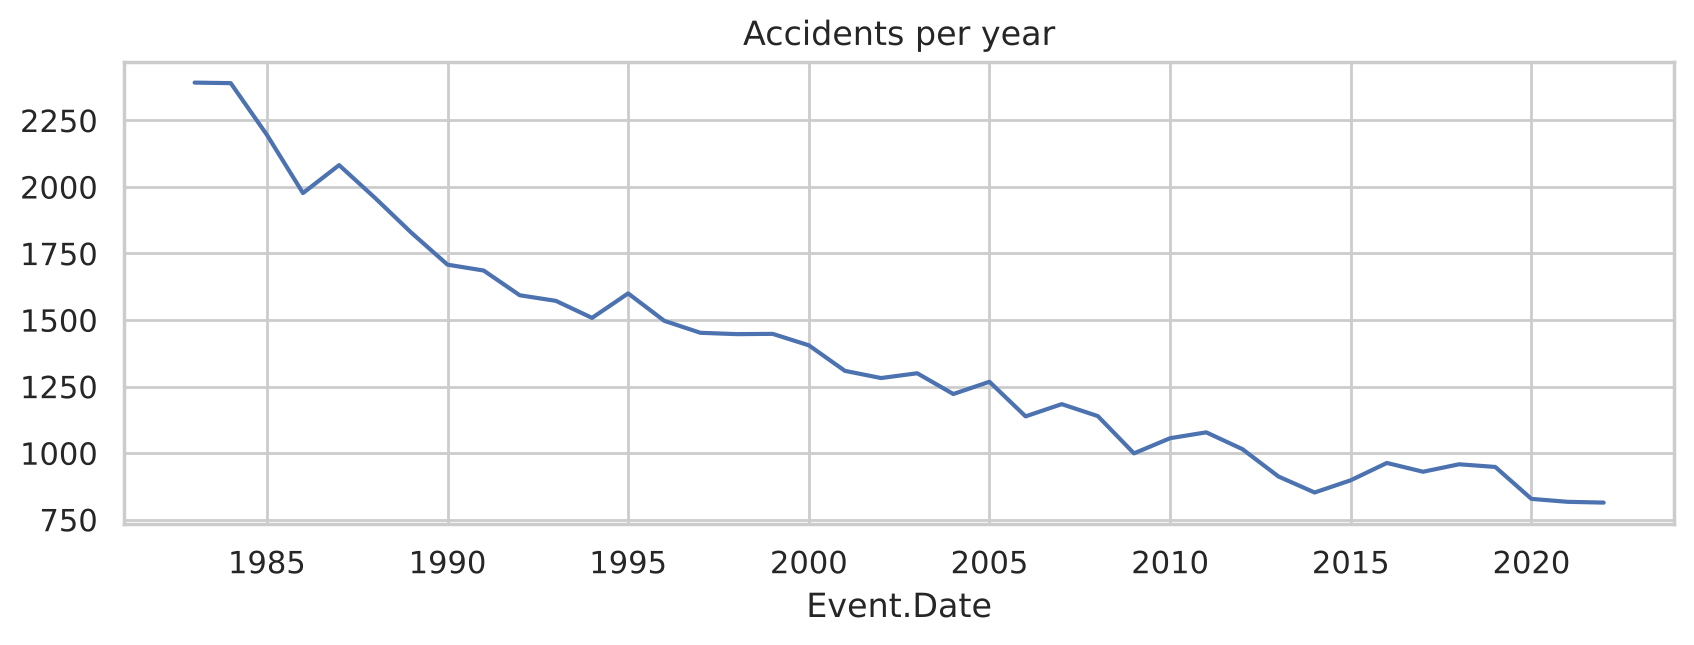

In [2]:
df = pd.read_csv('AviationData_cleaned.csv', parse_dates=['Event.Date'])
sns.set_theme(style='whitegrid')
print(df.shape)
print(df[['Total.Passengers', 'Fatal.Serious.Fraction', 'Destroyed']].describe().round(3))
df['Event.Date'].dt.year.value_counts().sort_index().plot(figsize=(10, 3), title='Accidents per year')

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [3]:
# A plane type (Make.Model) is "Large" if at least 10% of its accidents had 20 or more people on board,
# otherwise "Small". Using a share (not the maximum) avoids labelling a Cessna/Piper as large because of one
# outlier record, and avoids labelling a jet as small because a few flights carried only crew.
MIN_N = 10   # minimum number of accidents in a group, so that averages are robust
share20 = df['Total.Passengers'].ge(20).groupby(df['Make.Model']).mean()
df['Size'] = np.where(df['Make.Model'].map(share20) >= 0.10, 'Large', 'Small')
small = df[df['Size'] == 'Small']
large = df[df['Size'] == 'Large']
print(df['Size'].value_counts())
print('Plane types:', df.groupby('Size')['Make.Model'].nunique().to_dict(), '| Makes:', df.groupby('Size')['Make'].nunique().to_dict())

Size
Small    53671
Large      978
Name: count, dtype: int64
Plane types: {'Large': 297, 'Small': 2170} | Makes: {'Large': 13, 'Small': 45}


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

                    n  mean_frac  destroyed_rate
Make                                            
BOMBARDIER         15      0.104           0.067
WACO               97      0.132           0.103
SCHWEIZER         306      0.141           0.193
GREAT LAKES        53      0.142           0.113
MAULE             488      0.157           0.088
HELIO              67      0.171           0.164
BOEING            353      0.180           0.130
SWEARINGEN        111      0.194           0.189
WEATHERLY          77      0.195           0.208
AVIAT             221      0.201           0.063
STINSON           390      0.205           0.133
GRUMMAN          1165      0.218           0.251
WSK PZL MIELEC     60      0.225           0.250
LUSCOMBE          362      0.230           0.099
CESSNA          24485      0.243           0.189
                     n  mean_frac  destroyed_rate
Make                                             
MCDONNELL DOUGLAS  117      0.075           0.145
BOMBARDIER       

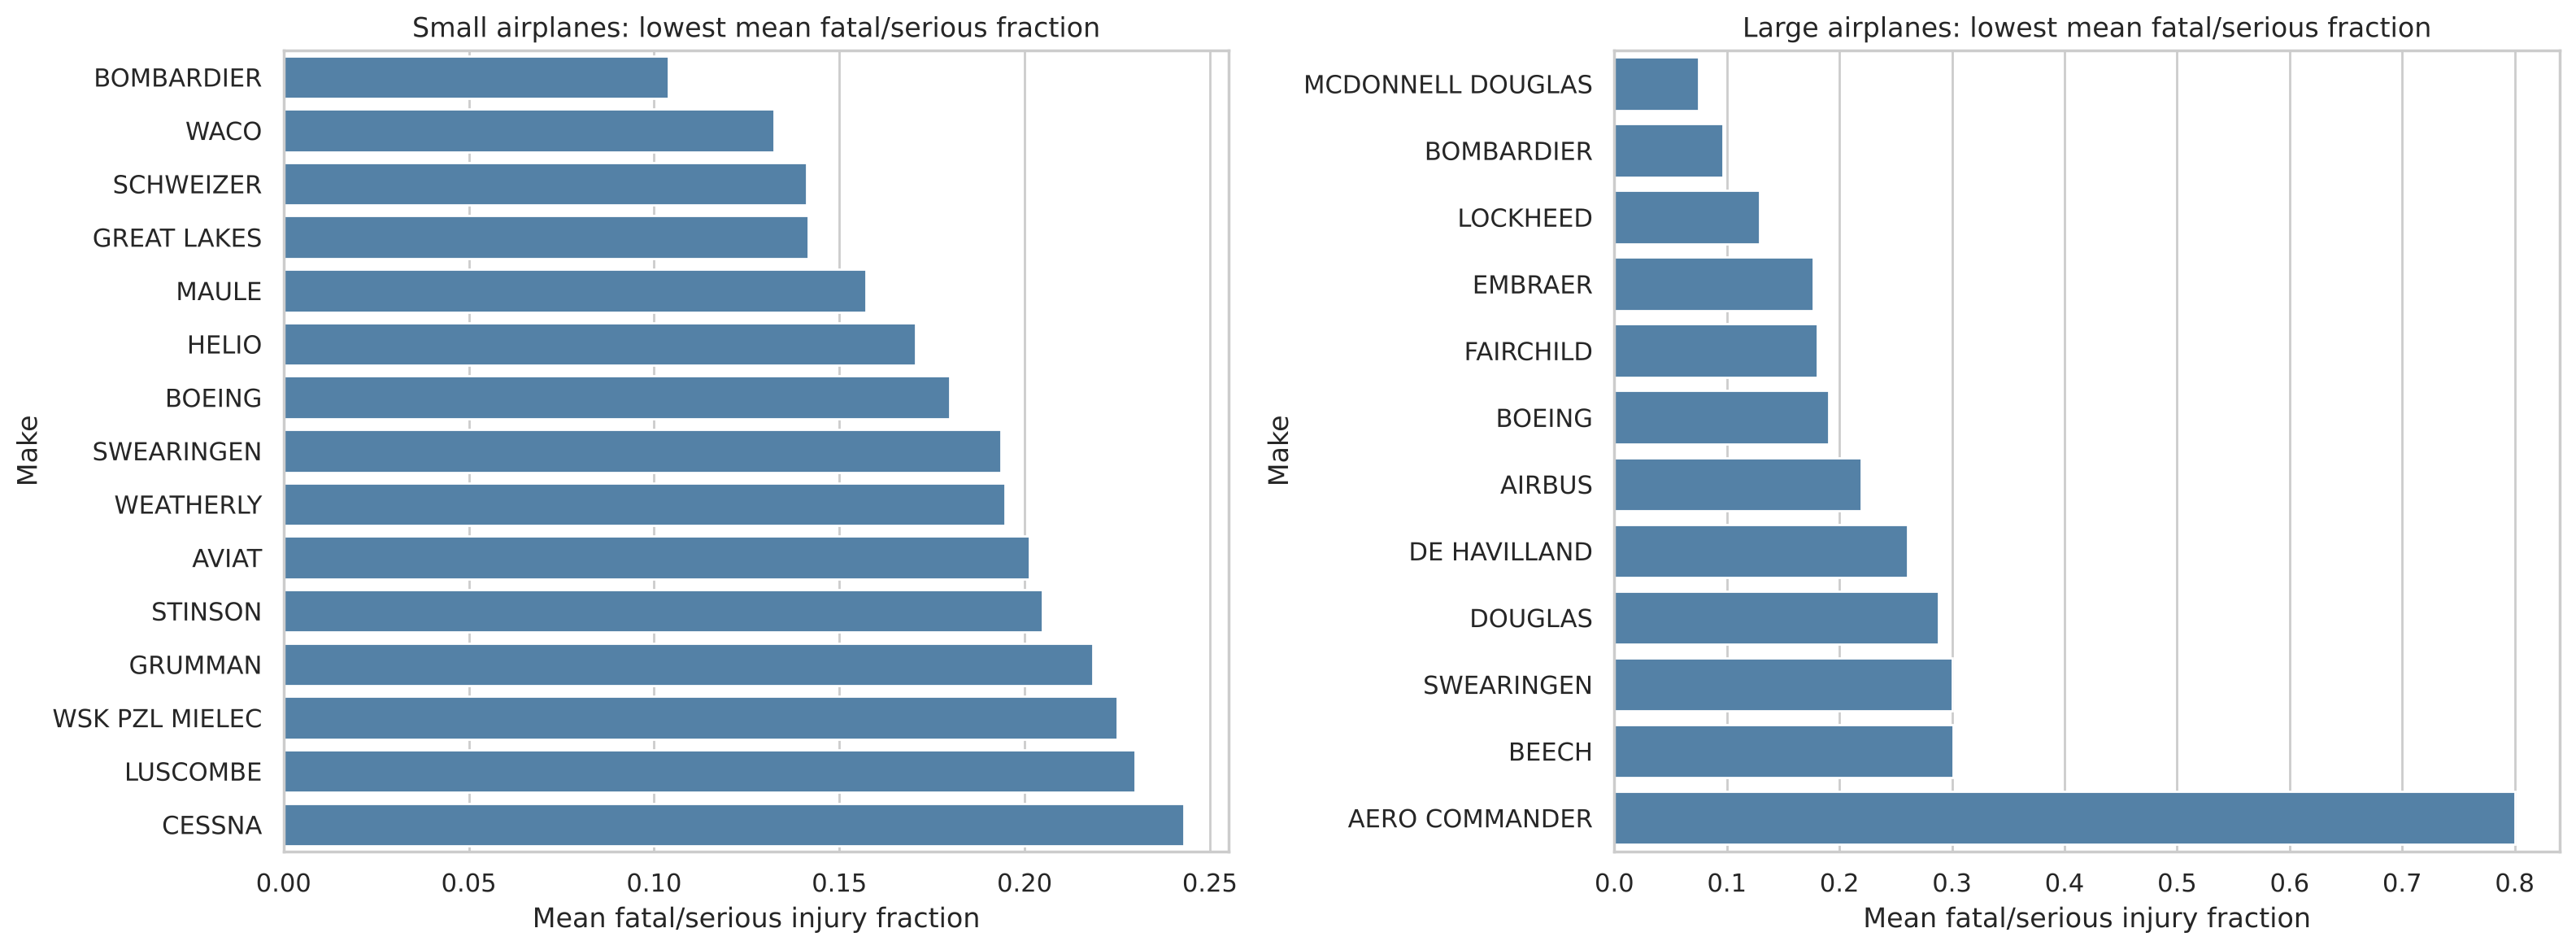

In [4]:
def make_stats(d):
    g = d.groupby('Make').agg(n=('Destroyed', 'size'),
                              mean_frac=('Fatal.Serious.Fraction', 'mean'),
                              destroyed_rate=('Destroyed', 'mean'))
    return g[g['n'] >= MIN_N]          # keep makes with at least 10 accidents

small_makes, large_makes = make_stats(small), make_stats(large)
small_low15 = small_makes.nsmallest(15, 'mean_frac')
large_low15 = large_makes.nsmallest(15, 'mean_frac')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, d, t in zip(axes, [small_low15, large_low15], ['Small airplanes', 'Large airplanes']):
    sns.barplot(x=d['mean_frac'], y=d.index, ax=ax, color='steelblue')
    ax.set(title=f'{t}: lowest mean fatal/serious fraction', xlabel='Mean fatal/serious injury fraction', ylabel='Make')
plt.tight_layout()
print(small_low15.round(3)); print(large_low15.round(3))

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

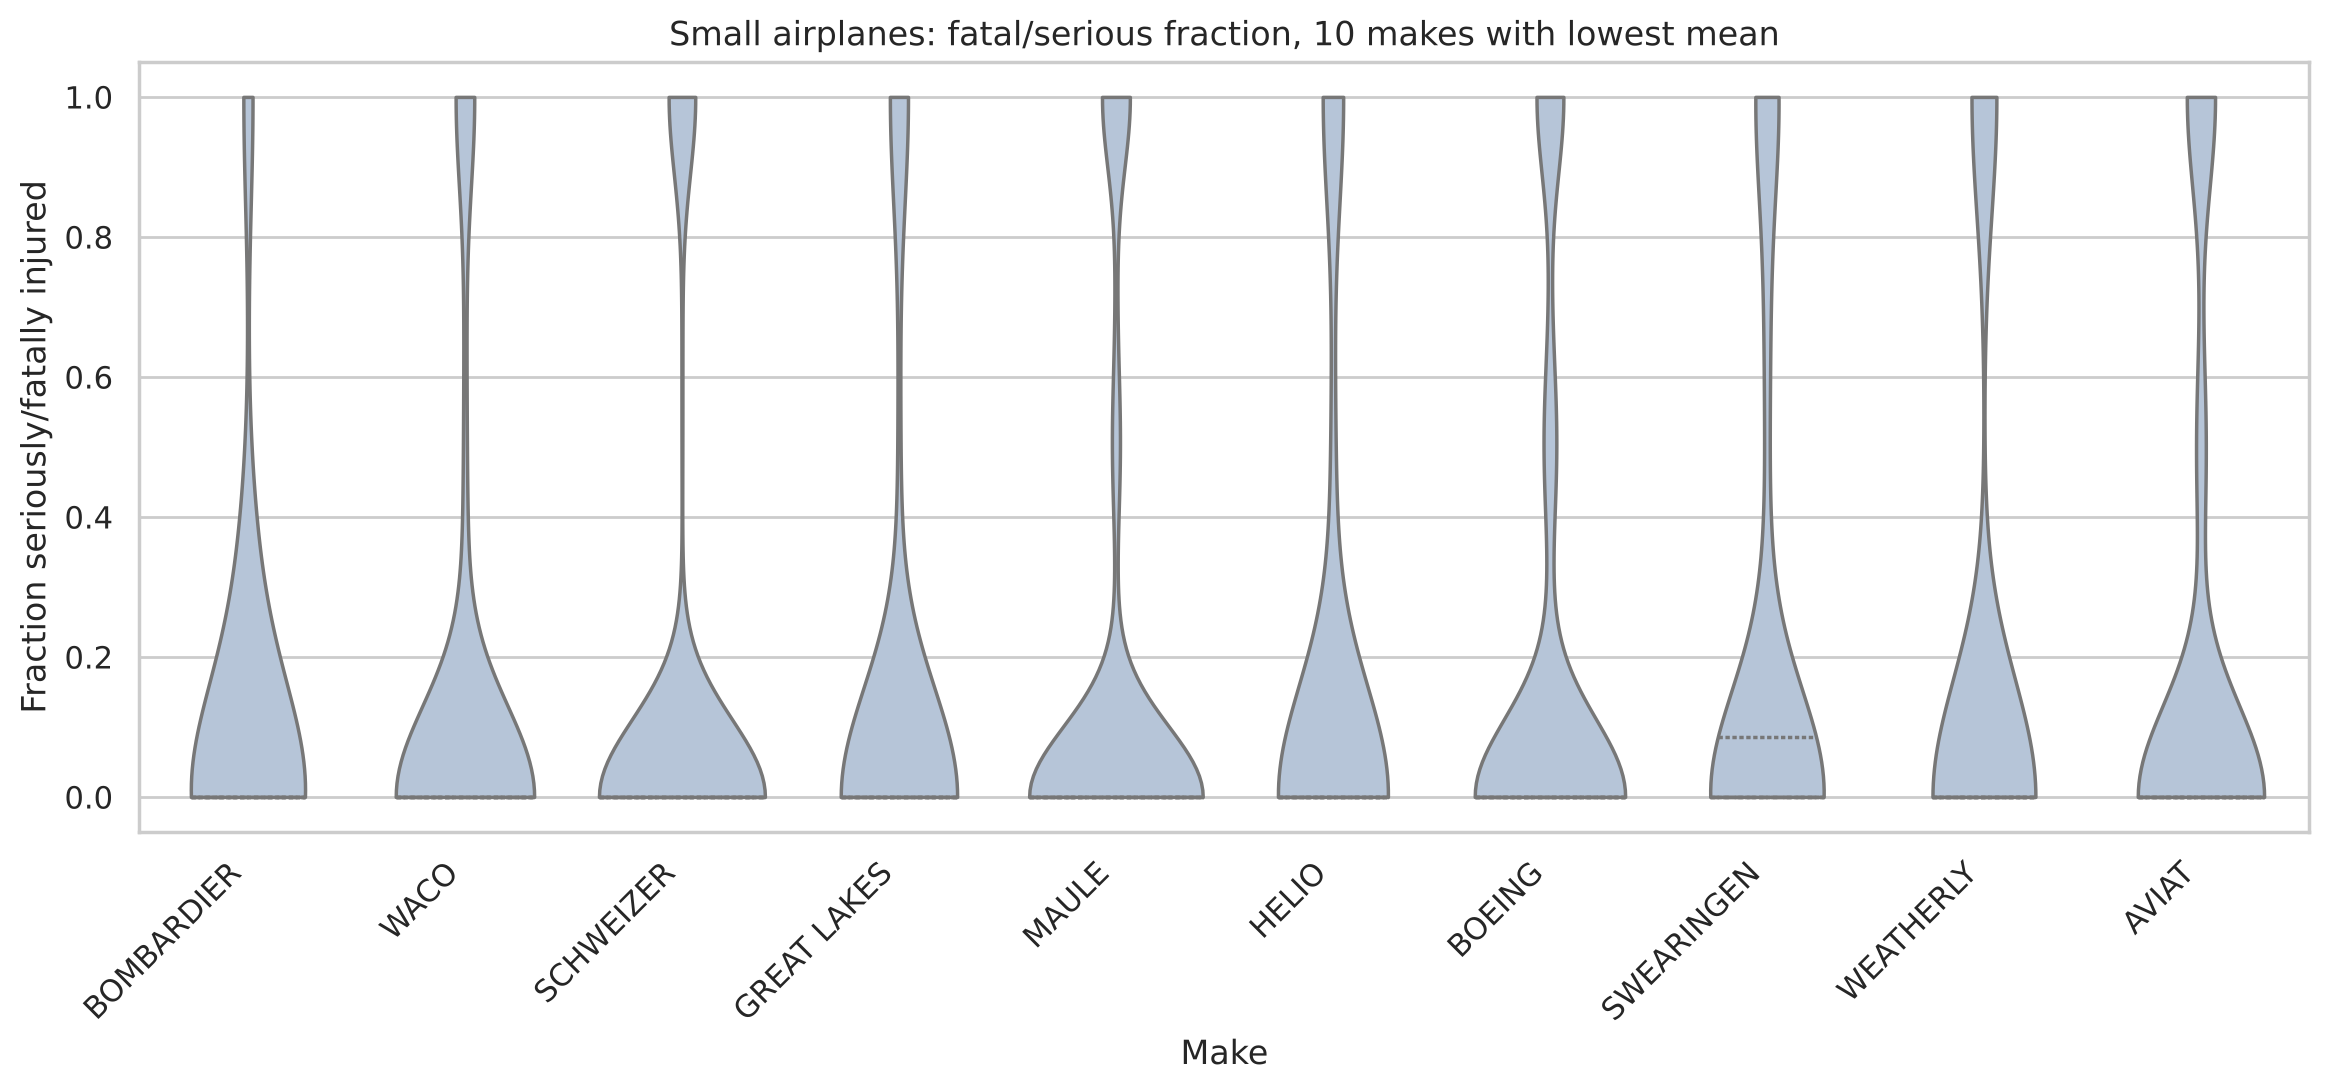

In [5]:
top10_small = small_makes.nsmallest(10, 'mean_frac').index
plt.figure(figsize=(14, 5))
sns.violinplot(data=small[small['Make'].isin(top10_small)], x='Make', y='Fatal.Serious.Fraction',
               order=top10_small, cut=0, inner='quartile', color='lightsteelblue')
plt.xticks(rotation=45, ha='right')
plt.title('Small airplanes: fatal/serious fraction, 10 makes with lowest mean')
plt.ylabel('Fraction seriously/fatally injured');

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

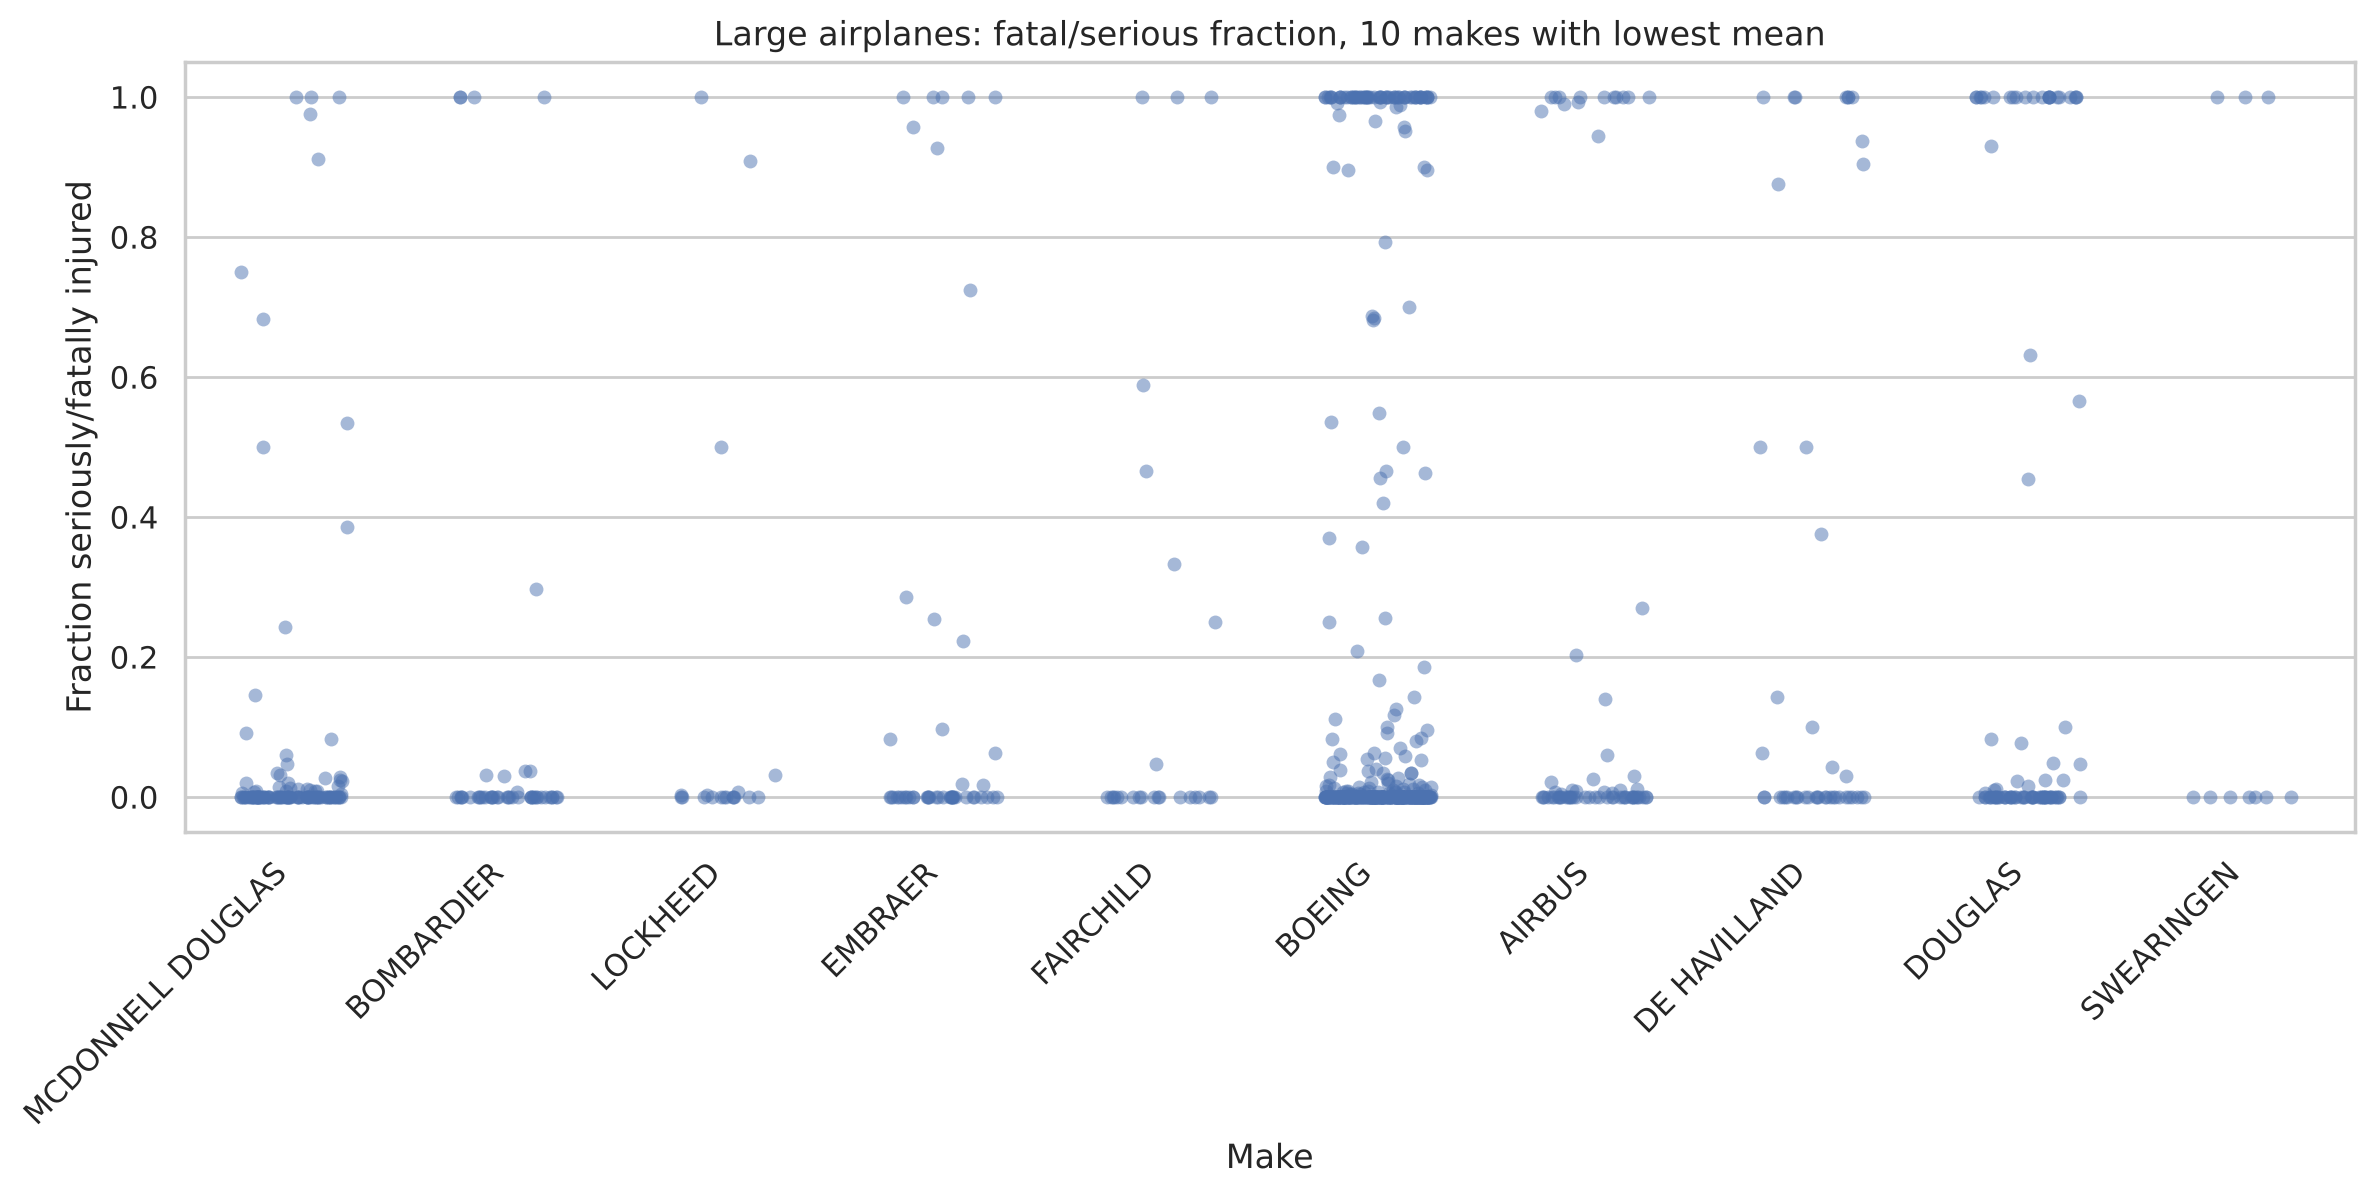

In [6]:
top10_large = large_makes.nsmallest(10, 'mean_frac').index
plt.figure(figsize=(14, 5))
sns.stripplot(data=large[large['Make'].isin(top10_large)], x='Make', y='Fatal.Serious.Fraction',
              order=top10_large, alpha=0.5, jitter=0.25)
plt.xticks(rotation=45, ha='right')
plt.title('Large airplanes: fatal/serious fraction, 10 makes with lowest mean')
plt.ylabel('Fraction seriously/fatally injured');

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

SMALL: lowest destruction rate by make
                n  destroyed_rate
Make                             
DIAMOND       120           0.058
AVIAT         221           0.063
BOMBARDIER     15           0.067
MAULE         488           0.088
LUSCOMBE      362           0.099
WACO           97           0.103
GREAT LAKES    53           0.113
TAYLORCRAFT   318           0.113
BOEING        353           0.130
AERONCA       527           0.133
STINSON       390           0.133
CHAMPION      526           0.135
DE HAVILLAND  331           0.142
GLOBE          80           0.162
HELIO          67           0.164

LARGE: lowest destruction rate by make
                     n  destroyed_rate
Make                                  
BOMBARDIER          46           0.087
MCDONNELL DOUGLAS  117           0.145
EMBRAER             49           0.163
BOEING             426           0.204
LOCKHEED            19           0.211
AIRBUS              67           0.239
BEECH               74         

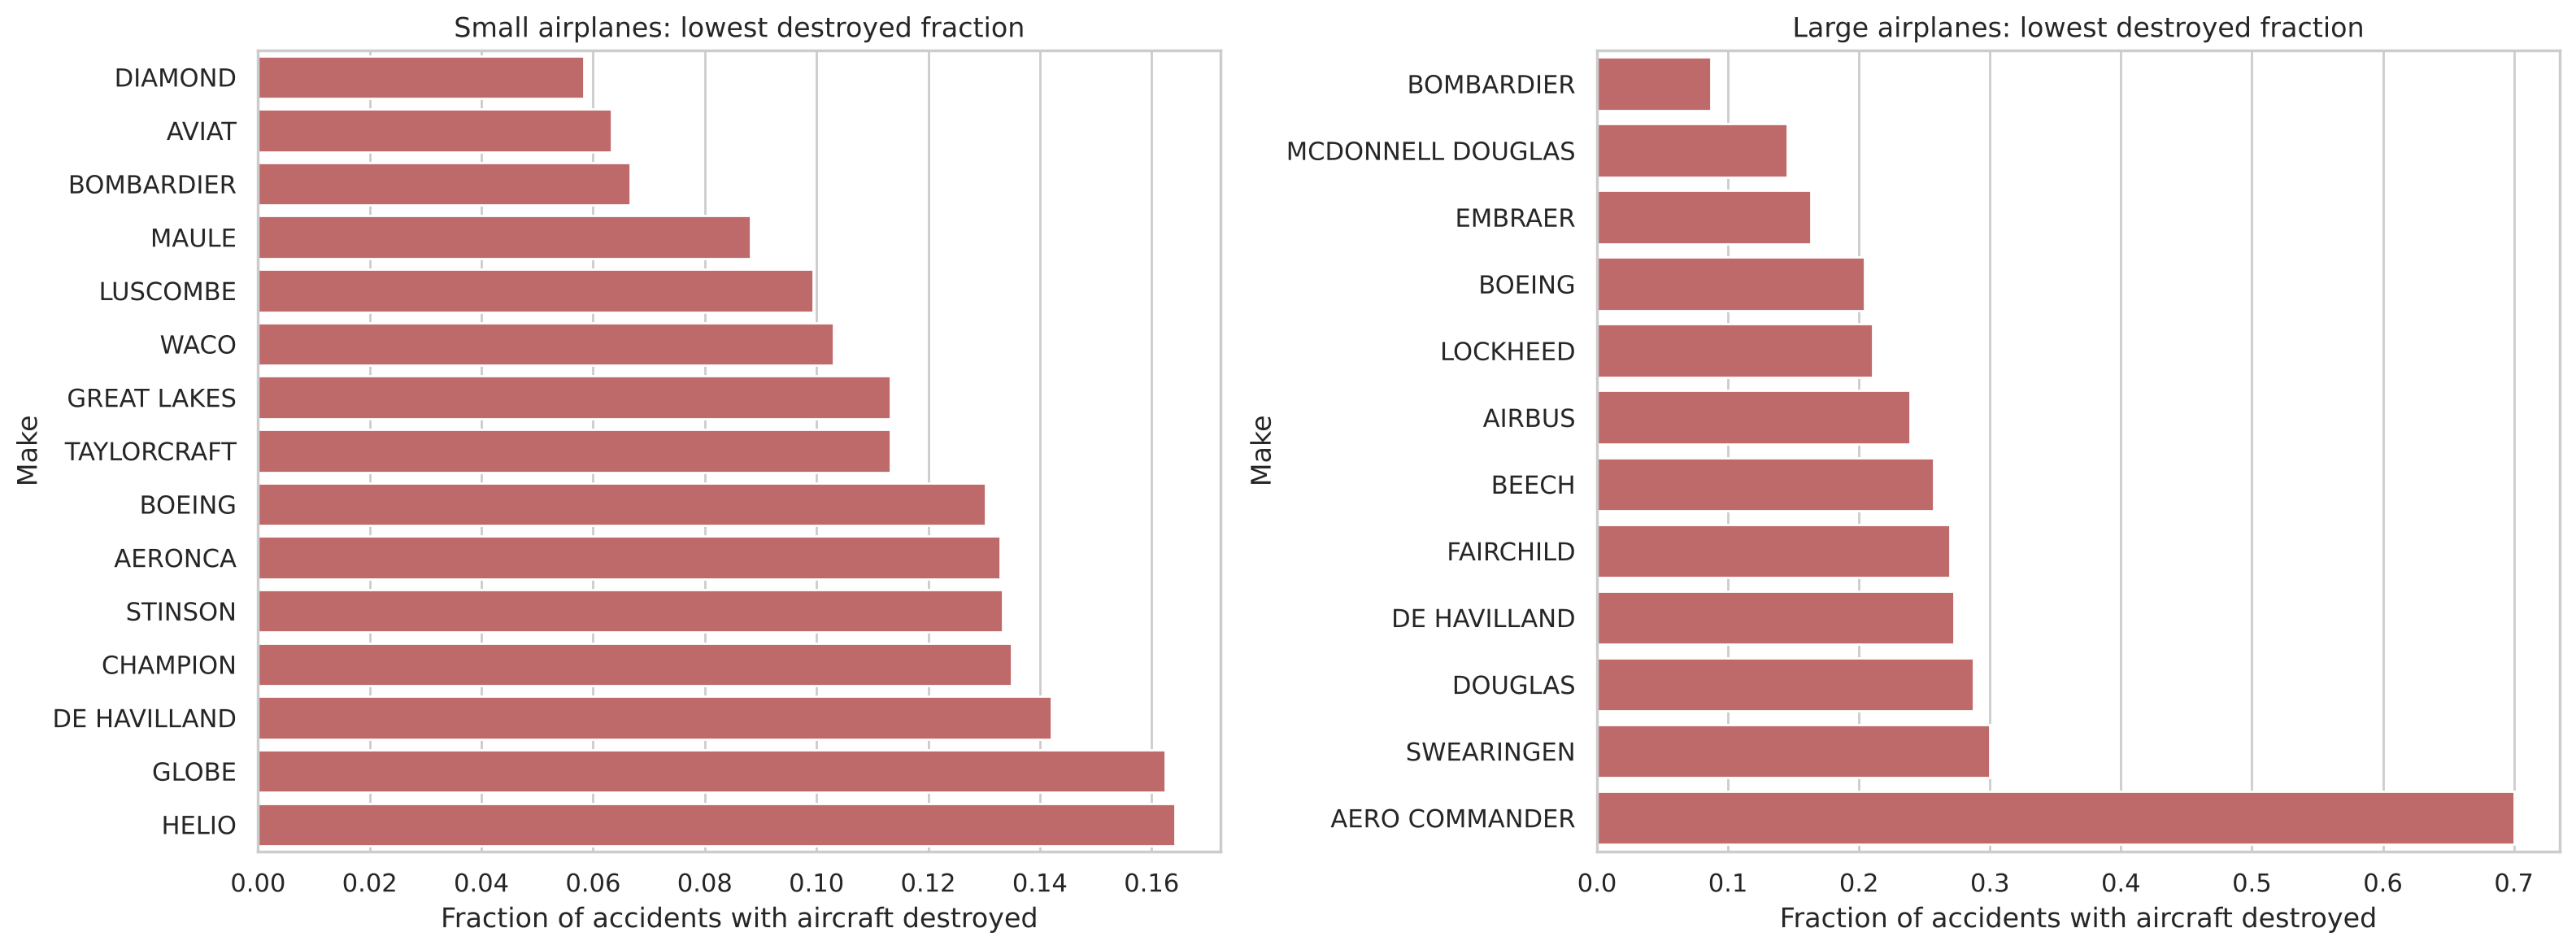

In [7]:
dest_small = small_makes.nsmallest(15, 'destroyed_rate')[['n', 'destroyed_rate']]
dest_large = large_makes.nsmallest(15, 'destroyed_rate')[['n', 'destroyed_rate']]
print('SMALL: lowest destruction rate by make'); print(dest_small.round(3))
print('\nLARGE: lowest destruction rate by make'); print(dest_large.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, d, t in zip(axes, [dest_small, dest_large], ['Small airplanes', 'Large airplanes']):
    sns.barplot(x=d['destroyed_rate'], y=d.index, ax=ax, color='indianred')
    ax.set(title=f'{t}: lowest destroyed fraction', xlabel='Fraction of accidents with aircraft destroyed', ylabel='Make')
plt.tight_layout()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

                          n  mean_frac  destroyed_rate
Make.Model                                            
MCDONNELL DOUGLAS MD-88  10      0.006           0.000
BOMBARDIER CL-600-2B19   14      0.007           0.000
MCDONNELL DOUGLAS MD-11  14      0.093           0.214
BOEING 727-200           11      0.095           0.091
BOEING 737-300           15      0.109           0.200
BEECH 1900D              30      0.137           0.133
BOEING 747               14      0.150           0.143
FAIRCHILD SA227-AC       16      0.164           0.250
BOEING 767               13      0.176           0.231
DOUGLAS DC-3C            17      0.235           0.176
BOEING 737               65      0.248           0.200
SWEARINGEN SA-226TC      10      0.300           0.300
DE HAVILLAND DHC-6-300   20      0.308           0.350
DOUGLAS DC-3             25      0.378           0.360
BOEING 737-400           10      0.384           0.500
BEECH 1900               13      0.395           0.308
BEECH 1900

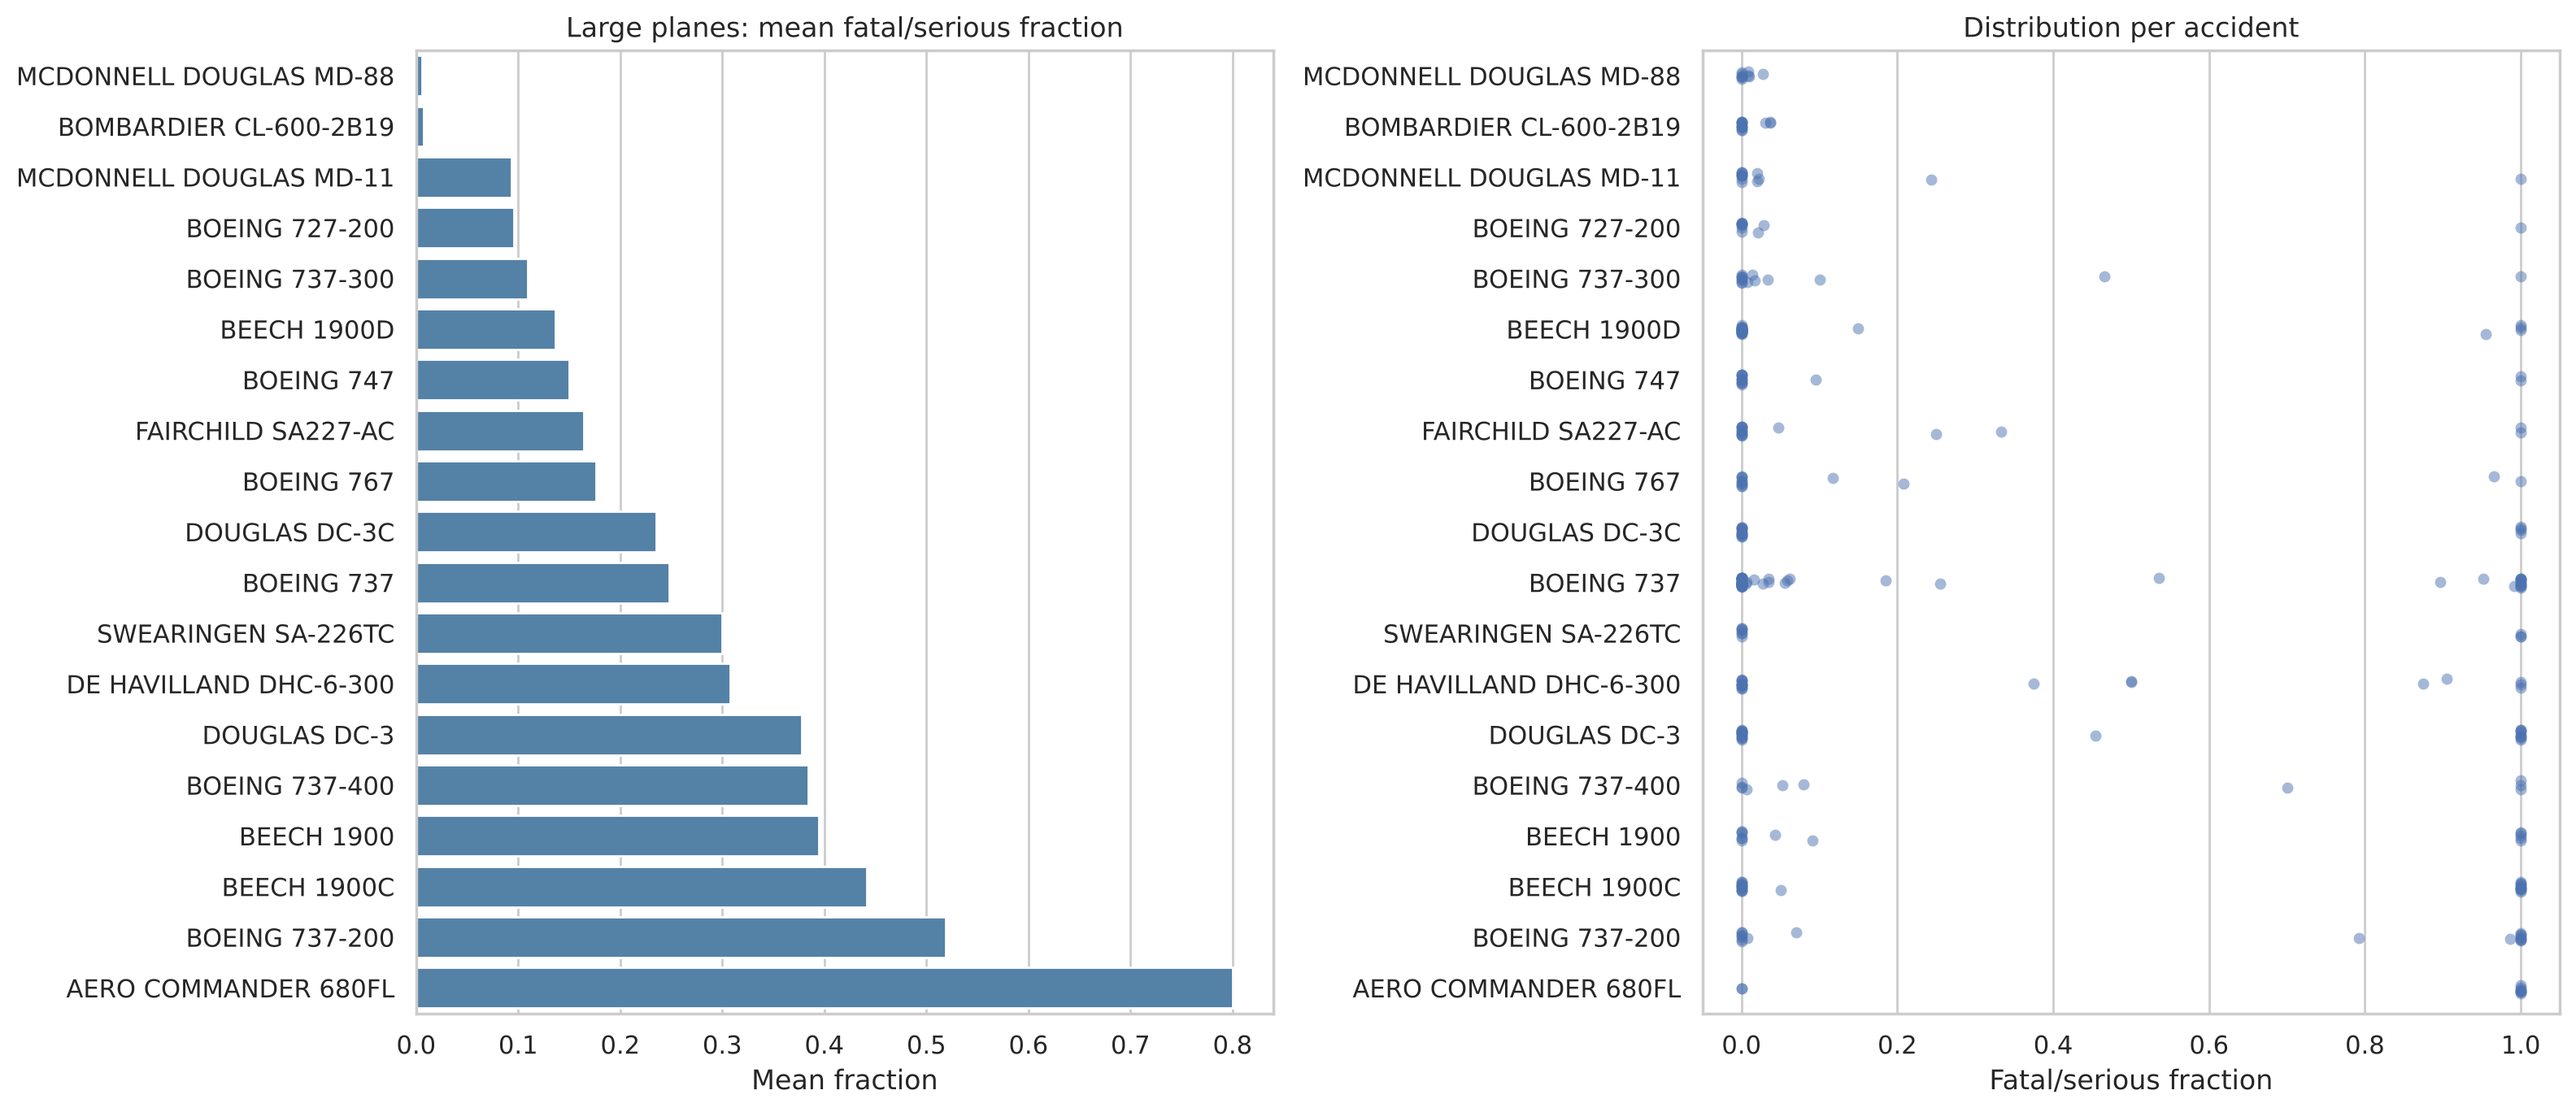

In [8]:
large_types = large.groupby('Make.Model').agg(n=('Destroyed', 'size'),
                                              mean_frac=('Fatal.Serious.Fraction', 'mean'),
                                              destroyed_rate=('Destroyed', 'mean'))
large_types = large_types[large_types['n'] >= MIN_N].sort_values('mean_frac')   # at least ten examples per type
print(large_types.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.barplot(x=large_types['mean_frac'], y=large_types.index, ax=axes[0], color='steelblue')
axes[0].set(title='Large planes: mean fatal/serious fraction', xlabel='Mean fraction', ylabel='')
sns.stripplot(data=large[large['Make.Model'].isin(large_types.index)], x='Fatal.Serious.Fraction', y='Make.Model',
              order=large_types.index, alpha=0.5, ax=axes[1])
axes[1].set(title='Distribution per accident', xlabel='Fatal/serious fraction', ylabel='')
plt.tight_layout()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

                       n  mean_frac  destroyed_rate
Make.Model                                         
MAULE MX-7-235        17      0.029           0.000
MAULE M-7-235B        10      0.050           0.000
MAULE M-4             18      0.056           0.056
WEATHERLY 201B        27      0.074           0.111
BOEING E75            33      0.076           0.121
SCHWEIZER G-164A      84      0.091           0.179
SWEARINGEN SA226TC    19      0.105           0.105
MAULE M-4-220C        37      0.108           0.081
GREAT LAKES 2T-1A-2   38      0.118           0.132
MAULE MX7             18      0.125           0.000
BOEING A75N1(PT17)    30      0.133           0.033
BOEING E75N1          11      0.136           0.091
MAULE M-7-235         26      0.142           0.077
MAULE M-7-235C        14      0.143           0.071
SWEARINGEN SA-226T    14      0.143           0.214
HELIO H-295           36      0.153           0.083
HELIO H-250           13      0.154           0.154
MAULE M-5-18

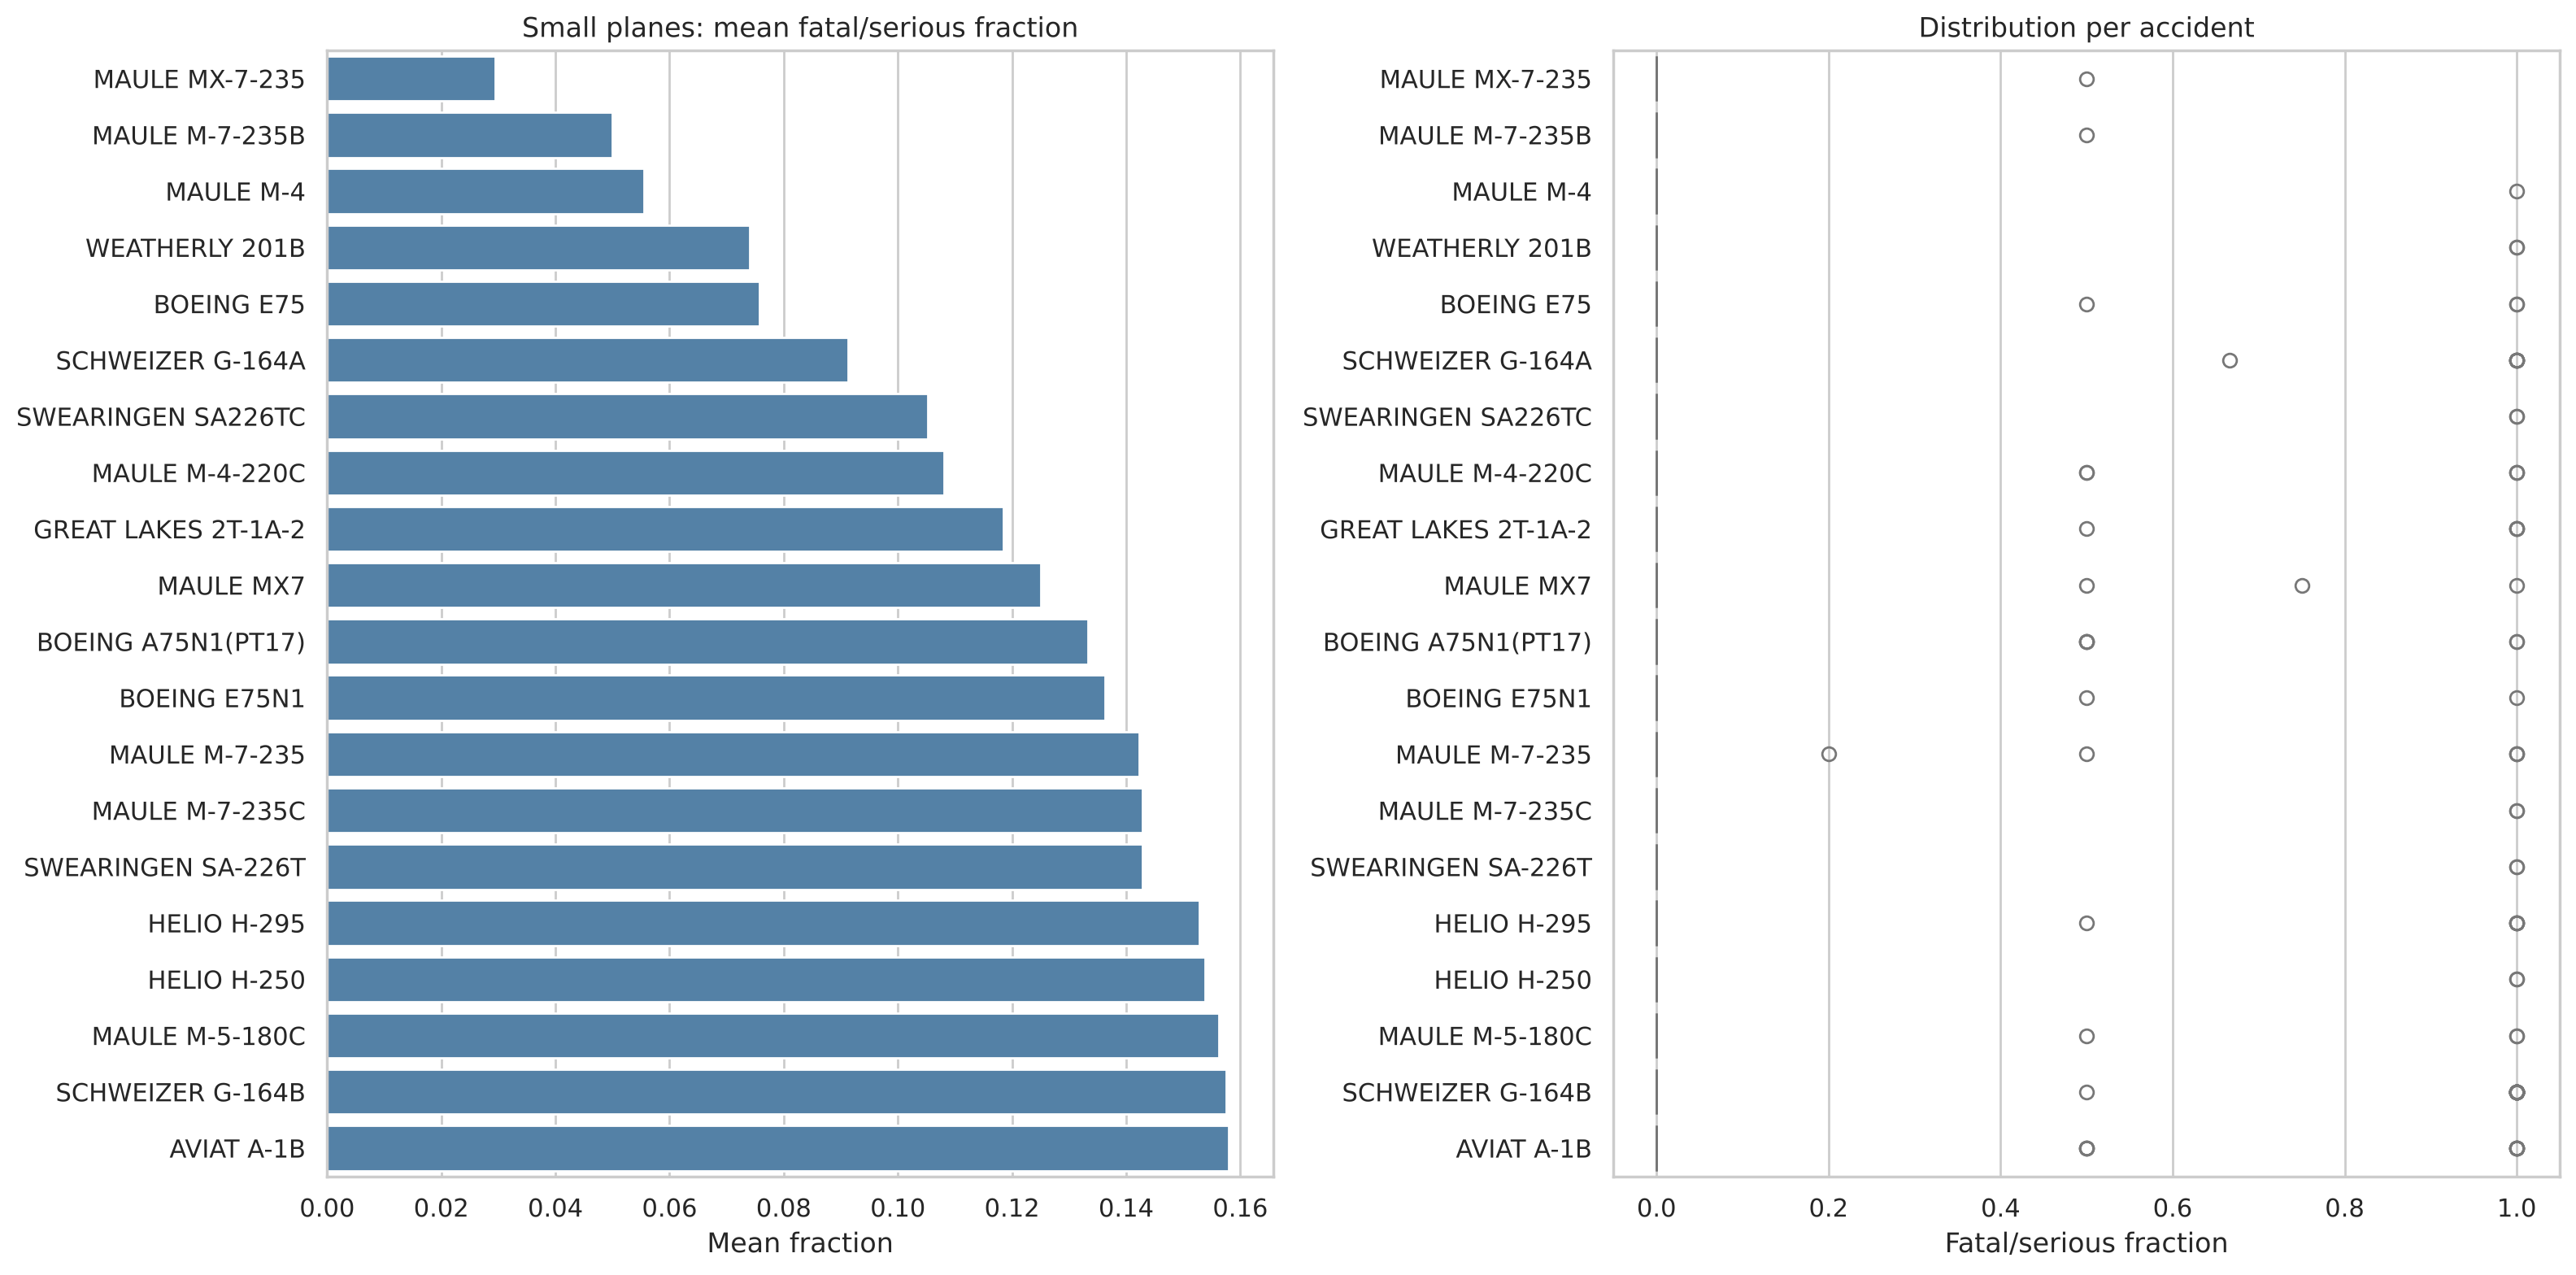

In [9]:
# Small planes: only models of the 10 makes with the lowest mean fatal/serious fraction, at least ten accidents per model
small_types = small[small['Make'].isin(top10_small)].groupby('Make.Model').agg(
    n=('Destroyed', 'size'), mean_frac=('Fatal.Serious.Fraction', 'mean'), destroyed_rate=('Destroyed', 'mean'))
small_types = small_types[small_types['n'] >= MIN_N].nsmallest(20, 'mean_frac')    # show the 20 best models
print(small_types.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
sns.barplot(x=small_types['mean_frac'], y=small_types.index, ax=axes[0], color='steelblue')
axes[0].set(title='Small planes: mean fatal/serious fraction', xlabel='Mean fraction', ylabel='')
sns.boxplot(data=small[small['Make.Model'].isin(small_types.index)], x='Fatal.Serious.Fraction', y='Make.Model',
            order=small_types.index, ax=axes[1], color='lightsteelblue')
axes[1].set(title='Distribution per accident', xlabel='Fatal/serious fraction', ylabel='')
plt.tight_layout()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

                       n  mean_frac  destroyed_rate
Weather.Condition                                  
VMC                48217      0.224           0.166
IMC                 4351      0.678           0.591


Mann-Whitney U (fatal/serious fraction, IMC vs VMC): p = < 1e-300
Chi-square (destroyed vs weather): p = < 1e-300


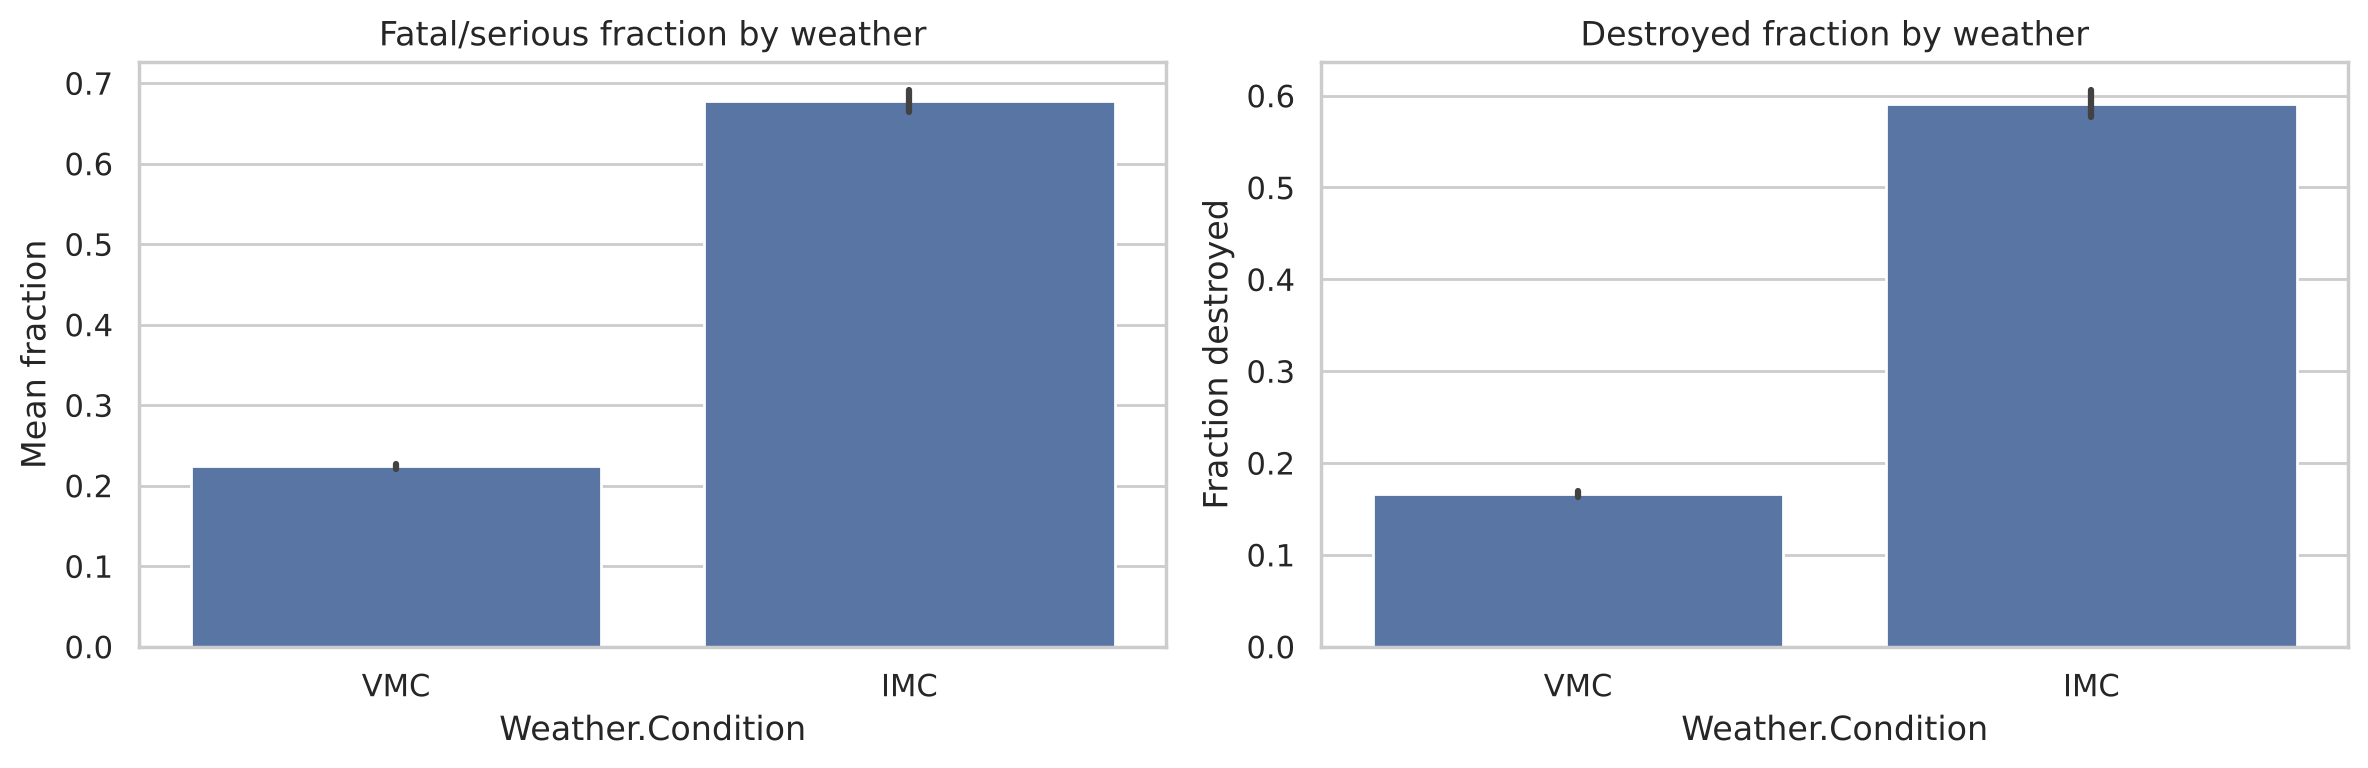

In [10]:
from scipy import stats

def fmt_p(p):
    return '< 1e-300' if p < 1e-300 else f'{p:.2e}'

def factor_summary(col, d=df, min_n=MIN_N):
    g = d.groupby(col).agg(n=('Destroyed', 'size'), mean_frac=('Fatal.Serious.Fraction', 'mean'),
                           destroyed_rate=('Destroyed', 'mean'))
    return g[g['n'] >= 30].sort_values('mean_frac')      # robust groups only (>= 30 accidents)

# FACTOR 1: Weather condition (VMC = good visibility, IMC = instrument conditions)
w = factor_summary('Weather.Condition')
print(w.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=df, x='Weather.Condition', y='Fatal.Serious.Fraction', ax=axes[0], order=w.index, errorbar=('ci', 95))
sns.barplot(data=df, x='Weather.Condition', y='Destroyed', ax=axes[1], order=w.index, errorbar=('ci', 95))
axes[0].set(title='Fatal/serious fraction by weather', ylabel='Mean fraction')
axes[1].set(title='Destroyed fraction by weather', ylabel='Fraction destroyed')
plt.tight_layout()

# Statistical tests: IMC vs VMC
v, i = (df.loc[df['Weather.Condition'] == c, 'Fatal.Serious.Fraction'].dropna() for c in ['VMC', 'IMC'])
print(f'Mann-Whitney U (fatal/serious fraction, IMC vs VMC): p = {fmt_p(stats.mannwhitneyu(i, v).pvalue)}')
ct = pd.crosstab(df['Weather.Condition'], df['Destroyed'])
print(f'Chi-square (destroyed vs weather): p = {fmt_p(stats.chi2_contingency(ct)[1])}')

**Factor 1: Weather condition.** Accidents in instrument conditions (IMC, n=4,351) are far more severe than in visual conditions (VMC, n=48,217): the mean fatal/serious fraction is 0.68 vs 0.22 (about 3x) and 59% of aircraft are destroyed vs 17%. The 95% confidence intervals do not overlap and both tests (Mann-Whitney and chi-square) give p < 1e-300, so the difference is statistically very robust. Interpretation: loss of visual references (spatial disorientation, controlled flight into terrain) tends to produce high-energy impacts. For an insurer, aircraft and operators flying in IMC deserve a higher risk loading.

                           n  mean_frac  destroyed_rate
Broad.phase.of.flight                                  
Taxi                    1304      0.017           0.021
Landing                10925      0.035           0.043
Standing                 436      0.092           0.126
Takeoff                 8042      0.228           0.219
Go-around               1089      0.300           0.287
Descent                 1140      0.354           0.339
Approach                4150      0.356           0.303
Cruise                  6486      0.356           0.345
Other                     53      0.441           0.377
Climb                   1248      0.442           0.443
Maneuvering             4232      0.525           0.466


Kruskal-Wallis (fatal/serious fraction across phases): p = < 1e-300
Chi-square (destroyed vs phase): p = < 1e-300


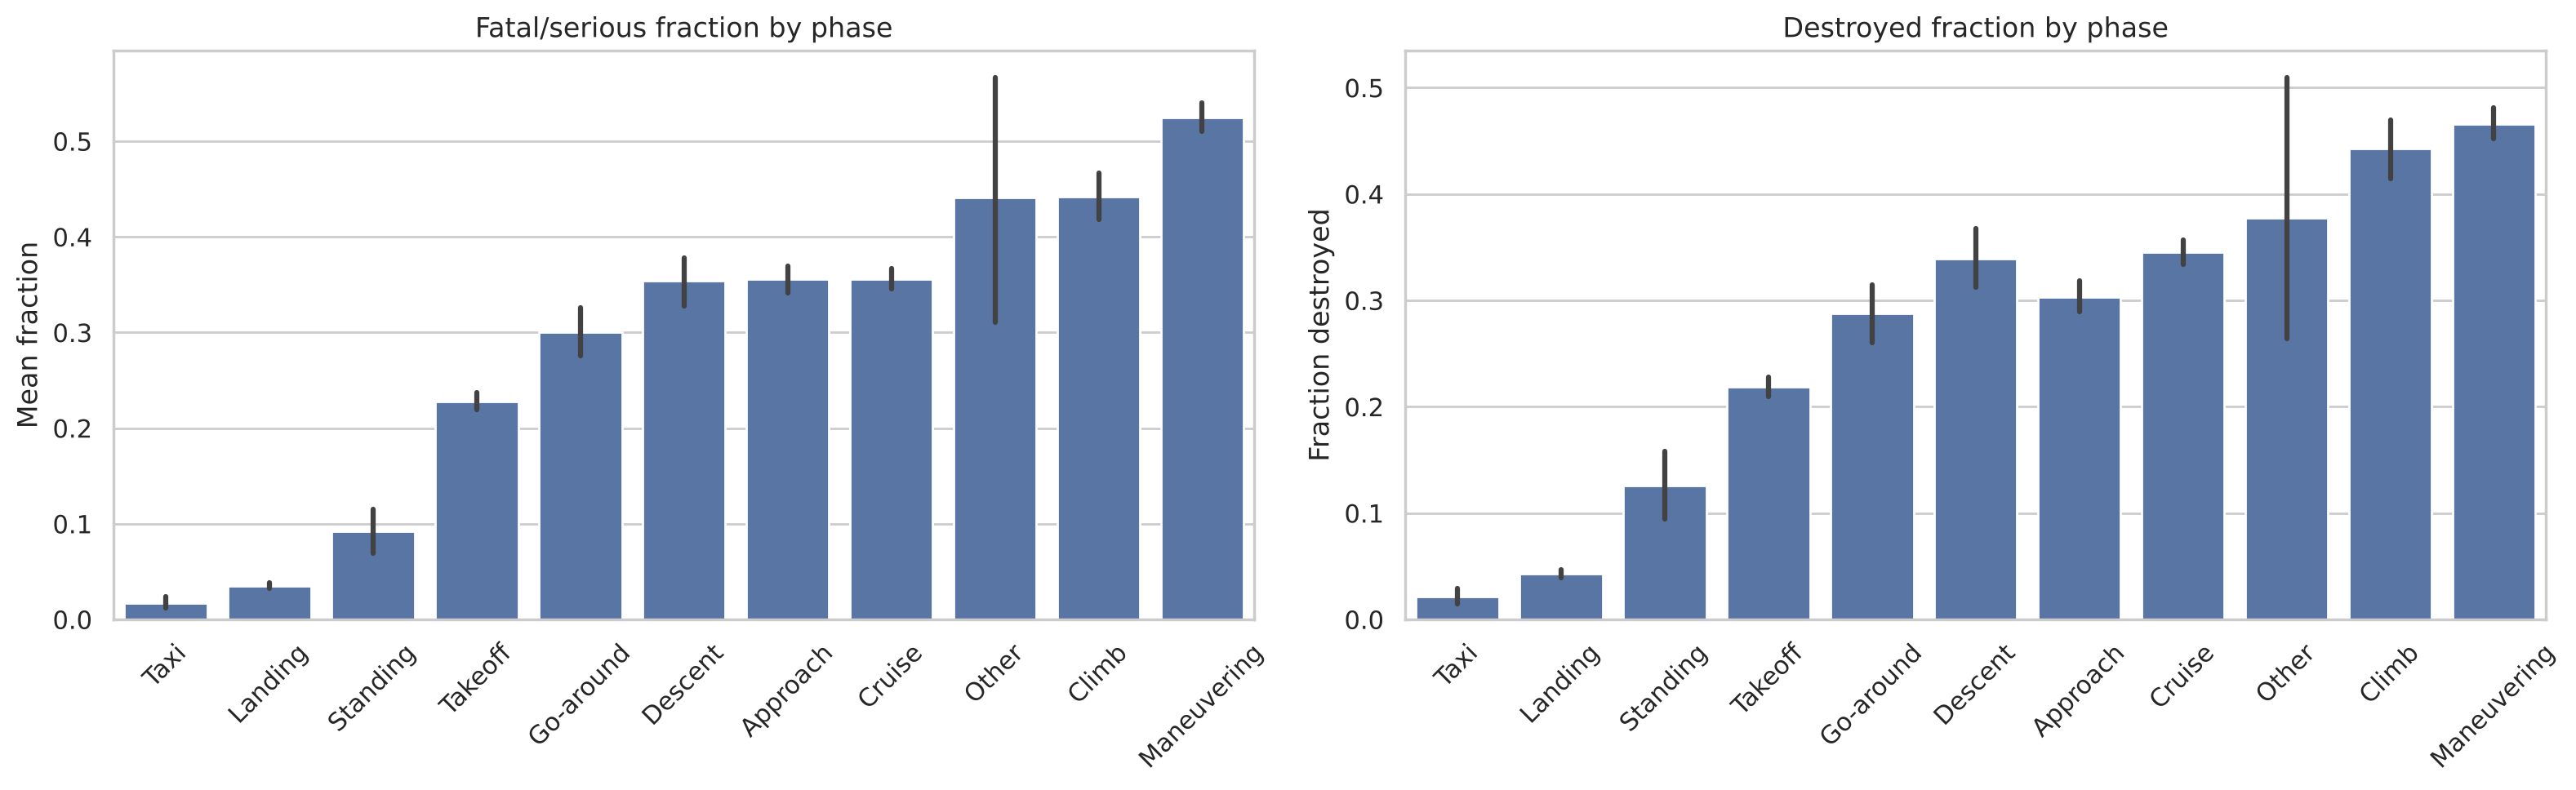

In [11]:
# FACTOR 2: Broad phase of flight
p = factor_summary('Broad.phase.of.flight')
print(p.round(3))
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=df, x='Broad.phase.of.flight', y='Fatal.Serious.Fraction', order=p.index, ax=axes[0], errorbar=('ci', 95))
sns.barplot(data=df, x='Broad.phase.of.flight', y='Destroyed', order=p.index, ax=axes[1], errorbar=('ci', 95))
axes[0].set(title='Fatal/serious fraction by phase', ylabel='Mean fraction', xlabel='')
axes[1].set(title='Destroyed fraction by phase', ylabel='Fraction destroyed', xlabel='')
for ax in axes: ax.tick_params(axis='x', rotation=45)
plt.tight_layout()

groups = [g['Fatal.Serious.Fraction'].values for _, g in df[df['Broad.phase.of.flight'].isin(p.index)].groupby('Broad.phase.of.flight')]
print(f'Kruskal-Wallis (fatal/serious fraction across phases): p = {fmt_p(stats.kruskal(*groups).pvalue)}')
ct = pd.crosstab(df['Broad.phase.of.flight'], df['Destroyed'])
print(f'Chi-square (destroyed vs phase): p = {fmt_p(stats.chi2_contingency(ct)[1])}')

**Factor 2: Phase of flight.** Severity depends strongly on when the accident happens (Kruskal-Wallis and chi-square p < 1e-300). Low-speed phases near the ground are the safest: taxi (0.02 fatal/serious fraction, 2% destroyed, n=1,304) and landing (0.04, 4%, n=10,925). High-energy phases are the worst: maneuvering (0.53, 47% destroyed, n=4,232), climb (0.44, 44%), then cruise and approach (about 0.36). Takeoff sits in between (0.23). So a make/model with many accidents is not necessarily dangerous: if its accidents are mostly landing mishaps, the injury and destruction cost is low. Operators with a lot of aerial work or low-altitude maneuvering (aerial application, instruction) face the most severe outcomes.

In [12]:
# Bonus: number of engines, split by plane size
eng = df.groupby(['Size', 'Number.of.Engines']).agg(n=('Destroyed', 'size'), mean_frac=('Fatal.Serious.Fraction', 'mean'),
                                                   destroyed_rate=('Destroyed', 'mean'))
print(eng[eng['n'] >= 30].round(3))

                             n  mean_frac  destroyed_rate
Size  Number.of.Engines                                  
Large 2.0                  602      0.160           0.166
      3.0                   93      0.090           0.108
      4.0                   65      0.233           0.231
Small 1.0                45720      0.251           0.185
      2.0                 6067      0.372           0.330
      3.0                   31      0.086           0.194
      4.0                   71      0.363           0.352


**Bonus: number of engines (groups with n >= 30).** Among small planes, twin-engine aircraft have more severe accidents than single-engine ones (0.37 vs 0.25 fatal/serious fraction; 33% vs 19% destroyed; n=6,067 vs 45,720), probably because twins are faster, heavier and fly in more demanding conditions rather than because a second engine is a risk by itself. Large twin-engine planes (n=602) do better (0.16, 17% destroyed). Engine count alone is therefore not a good safety criterion; the make/model and the conditions matter more.